# Jigsaw Unintended Bias: EDA and Data Cleaning
**Member 1, Toxic Comment Detection and Explainable Content Moderation.** Dataset: Jigsaw 2019 `train.csv` only (no other datasets).

**What this notebook does**

1. **Audits** the raw file: structure, missing values, label distributions, annotator counts.
2. **Cleans** the comments with a reusable module (`toxic_preprocessing.py`) and reports exactly how many comments each rule touched.
3. **Explores** the cleaned data: lengths, characteristic words, time trends, and, most importantly for this project, how toxic the comments that mention each identity group are.
4. **Splits** into train/val/test (grouped by article, so threads never leak across splits) and **saves** everything the team needs.

**Design decisions**

| Decision | Choice | Why |
|---|---|---|
| Encoding damage | Repair mojibake (`Iâ€™ll` becomes `I'll`) | `train.csv` has UTF-8 text that was decoded as Windows-1252, which would otherwise create junk tokens |
| Cleaning level | Light: unescape HTML, Unicode NFKC, straighten curly quotes, mask URLs and @mentions, squeeze repeated characters | Keeps capitalization, punctuation and identity terms, which carry signal and are the subject of the fairness study |
| Stop words / stemming | **Not removed** | "I", "am", "a" matter for cases like *"I am a gay woman"* |
| Duplicates | Merge identical texts and **average their annotator scores** | Identical comments can carry conflicting labels; averaging is more faithful than picking one at random |
| Binary labels | Annotator fraction >= 0.5, continuous scores also kept | Standard Jigsaw convention, with soft labels still available |
| Modelling labels | Chosen automatically: labels with enough positives only | Some labels are too rare at 0.5 to train or evaluate |
| Split | Stratified, **grouped by `article_id`** | Comments under one article share topics and quotes; a random split would inflate scores |

> **Note on the saved outputs.** `train.csv` was too large to share, so the outputs stored in this copy were generated on `test_public_expanded.csv` (97,320 real Jigsaw comments with the same schema and labels). Counts and rates will change when you run it on `train.csv` (about 1.8M rows). Delete this note after re-running.

## 1. Setup and configuration

In [1]:
# Uncomment on a fresh machine / Colab:
# %pip install -q pandas scikit-learn matplotlib pyarrow

import os, re, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import CountVectorizer

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
np.random.seed(SEED)

OUT_DIR = Path("processed_data"); FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# ---------- where the data lives (edit if needed) ----------
JIGSAW_CANDIDATES = [
    os.environ.get("JIGSAW_CSV", ""),
    "/kaggle/input/jigsaw-unintended-bias-in-toxicity-classification/train.csv",   # Kaggle notebook
    "train.csv",                                                                    # next to this notebook
    "data/train.csv",
]

# ---------- tunable settings ----------
MAX_ROWS = None                    # e.g. 200_000 for a quick dry run (random sample); None = all rows
LABEL_THRESHOLD = 0.5              # annotator fraction >= 0.5 -> positive label
IDENTITY_MENTION_THRESHOLD = 0.5   # same rule the Kaggle competition used for subgroup metrics
MIN_POSITIVES_FOR_MODELLING = 500  # labels with fewer positives are kept in the file but not recommended for modelling
N_SPLIT_FOLDS = 10                 # 1 fold -> test, 1 fold -> val, the rest -> train (80/10/10)

# unified label name -> Jigsaw source column
LABEL_SOURCE = {
    "toxic": "target", "severe_toxic": "severe_toxicity", "obscene": "obscene", "threat": "threat",
    "insult": "insult", "identity_hate": "identity_attack", "sexual_explicit": "sexual_explicit",
}
LABELS_ALL = list(LABEL_SOURCE)

JIGSAW_IDENTITY_COLS = [
    "male", "female", "transgender", "other_gender", "heterosexual", "homosexual_gay_or_lesbian",
    "bisexual", "other_sexual_orientation", "christian", "jewish", "muslim", "hindu", "buddhist",
    "atheist", "other_religion", "black", "white", "asian", "latino", "other_race_or_ethnicity",
    "physical_disability", "intellectual_or_learning_disability", "psychiatric_or_mental_illness",
    "other_disability",
]
# the 9 groups the Kaggle competition used for its bias metrics (Member 3 will focus on these)
KEY_IDENTITIES = ["male", "female", "homosexual_gay_or_lesbian", "christian", "jewish",
                  "muslim", "black", "white", "psychiatric_or_mental_illness"]

c:\Users\shraw\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 2. Load the data

`train.csv` is large, so we load only the columns we need and store scores as `float32`. Jigsaw labels are **fractions of annotators** who gave a label (so `0.6` means 60% of raters). The overall toxicity column is called `target` in `train.csv` (the expanded test files call it `toxicity`; the loader accepts both).

In [3]:
jigsaw_path = next((p for p in JIGSAW_CANDIDATES if p and Path(p).exists()), None)
if jigsaw_path is None:
    raise FileNotFoundError(
        "train.csv not found. Download it from "
        "https://www.kaggle.com/c/jigsaw-unintended-bias-in-toxicity-classification/data "
        "(accept the rules first), then set JIGSAW_CSV or put train.csv next to this notebook.")

header = pd.read_csv(jigsaw_path, nrows=0).columns.tolist()
rename = {"toxicity": "target"} if ("target" not in header and "toxicity" in header) else {}
inv = {v: k for k, v in rename.items()}

wanted = (["id", "comment_text", "target", "severe_toxicity", "obscene", "identity_attack", "insult", "threat",
           "sexual_explicit", "created_date", "publication_id", "parent_id", "article_id", "rating", "likes",
           "disagree", "identity_annotator_count", "toxicity_annotator_count"] + JIGSAW_IDENTITY_COLS)
usecols = [inv.get(c, c) for c in wanted if inv.get(c, c) in header]

raw = pd.read_csv(jigsaw_path, usecols=usecols).rename(columns=rename)
missing = [c for c in ["id", "comment_text", "target", "severe_toxicity", "obscene", "identity_attack",
                       "insult", "threat"] if c not in raw.columns]
if missing:
    raise ValueError(f"Unexpected schema, missing columns: {missing}")

float_cols = raw.select_dtypes("float64").columns
raw[float_cols] = raw[float_cols].astype("float32")
id_cols = [c for c in JIGSAW_IDENTITY_COLS if c in raw.columns]

if MAX_ROWS and len(raw) > MAX_ROWS:
    raw = raw.sample(MAX_ROWS, random_state=SEED).reset_index(drop=True)

print(f"DATA FILE : {jigsaw_path}")
print(f"ROWS      : {len(raw):,}   COLUMNS: {raw.shape[1]}   MEMORY: {raw.memory_usage(deep=True).sum()/1e6:,.0f} MB")
raw.head(3)

DATA FILE : train.csv
ROWS      : 1,804,874   COLUMNS: 42   MEMORY: 979 MB


,id,target,comment_text,severe_toxicity,obscene,identity_attack,insult,threat,asian,atheist,bisexual,black,buddhist,christian,female,heterosexual,hindu,homosexual_gay_or_lesbian,intellectual_or_learning_disability,jewish,latino,male,muslim,other_disability,other_gender,other_race_or_ethnicity,other_religion,other_sexual_orientation,physical_disability,psychiatric_or_mental_illness,transgender,white,created_date,publication_id,parent_id,article_id,rating,likes,disagree,sexual_explicit,identity_annotator_count,toxicity_annotator_count
0,59848,0.0,"This is so cool. It's like, 'would you want your mother to read this??' Really great idea, well done!",0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-09-29 10:50:41.987077+00,2,NaN,2006,rejected,0,0,0.0,0,4
1,59849,0.0,"Thank you!! This would make my life a lot less anxiety-inducing. Keep it up, and don't let anyone get in y...",0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-09-29 10:50:42.870083+00,2,NaN,2006,rejected,0,0,0.0,0,4
2,59852,0.0,This is such an urgent design problem; kudos to you for taking it on. Very impressive!,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-09-29 10:50:45.222647+00,2,NaN,2006,rejected,0,0,0.0,0,4


## 3. Raw data audit

### 3.1 Structure and missing values

In [4]:
nulls = raw.isna().sum()
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": nulls, "missing_%": (nulls / len(raw) * 100).round(2)})
print("Columns with missing values:")
display(audit[audit["missing"] > 0])

has_id = raw[id_cols].notna().any(axis=1)
print(f"\nRows WITH identity annotations   : {has_id.sum():>9,}  ({has_id.mean():.1%})")
print(f"Rows WITHOUT identity annotations: {(~has_id).sum():>9,}  ({(~has_id).mean():.1%})")
print("Identity columns are filled for ALL 24 groups or none:", bool((raw[id_cols].notna().sum(axis=1).isin([0, len(id_cols)])).all()))
print("\nA NaN identity value means 'nobody annotated this comment for identity', NOT 'no identity mentioned'.")
print("-> we keep NaN as NaN and track availability in has_identity_labels.")

Columns with missing values:


,dtype,missing,missing_%
comment_text,str,3,0.00
asian,float32,1399744,77.55
atheist,float32,1399744,77.55
bisexual,float32,1399744,77.55
black,float32,1399744,77.55
buddhist,float32,1399744,77.55
christian,float32,1399744,77.55
female,float32,1399744,77.55
heterosexual,float32,1399744,77.55
hindu,float32,1399744,77.55



Rows WITH identity annotations   :   405,130  (22.4%)
Rows WITHOUT identity annotations: 1,399,744  (77.6%)
Identity columns are filled for ALL 24 groups or none: True

A NaN identity value means 'nobody annotated this comment for identity', NOT 'no identity mentioned'.
-> we keep NaN as NaN and track availability in has_identity_labels.


### 3.2 The target is a fraction of raters, not a 0/1 label

The histogram shows how many comments sit near the 0.5 cut-off. Those borderline comments are where annotators disagreed, and where any threshold choice changes the dataset.

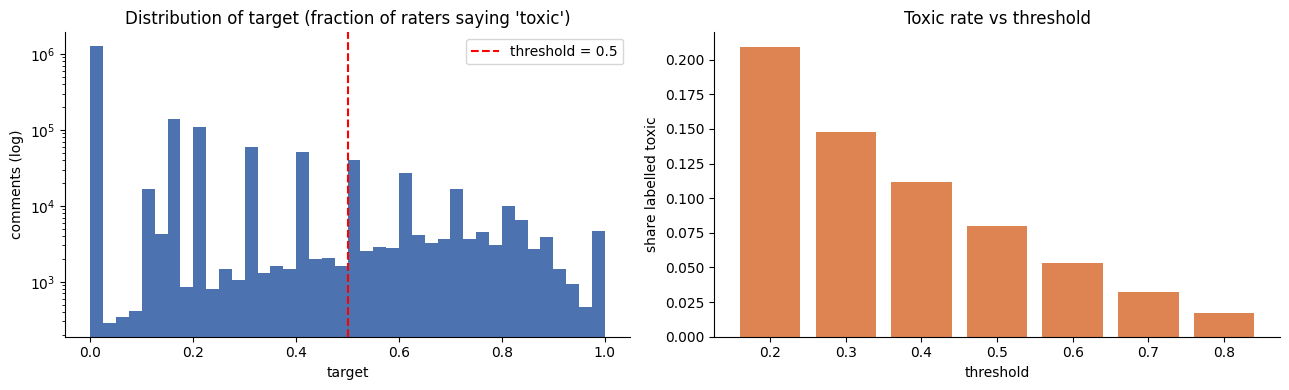

,threshold,n_toxic,toxic_rate
0,0.2,377686,0.2093
1,0.3,266089,0.1474
2,0.4,201476,0.1116
3,0.5,144334,0.0800
4,0.6,96410,0.0534
5,0.7,58674,0.0325
6,0.8,30831,0.0171


Borderline comments (0.2 < target < 0.8): 13.26% of the data
Exactly zero toxicity: 70.1%   |   Class balance at 0.5: 8.00% toxic


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(raw["target"], bins=40, color="#4c72b0")
ax[0].set_yscale("log"); ax[0].axvline(LABEL_THRESHOLD, color="red", ls="--", label=f"threshold = {LABEL_THRESHOLD}")
ax[0].set_title("Distribution of target (fraction of raters saying 'toxic')"); ax[0].set_xlabel("target"); ax[0].set_ylabel("comments (log)"); ax[0].legend()

thr = pd.DataFrame([{"threshold": t, "n_toxic": int((raw["target"] >= t).sum()), "toxic_rate": float((raw["target"] >= t).mean())}
                    for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]])
ax[1].bar(thr["threshold"].astype(str), thr["toxic_rate"], color="#dd8452")
ax[1].set_title("Toxic rate vs threshold"); ax[1].set_xlabel("threshold"); ax[1].set_ylabel("share labelled toxic")
plt.tight_layout(); savefig("01_target_distribution"); plt.show()

display(thr.round(4))
border = ((raw["target"] > 0.2) & (raw["target"] < 0.8)).mean()
print(f"Borderline comments (0.2 < target < 0.8): {border:.2%} of the data")
print(f"Exactly zero toxicity: {(raw['target'] == 0).mean():.1%}   |   Class balance at {LABEL_THRESHOLD}: {(raw['target'] >= LABEL_THRESHOLD).mean():.2%} toxic")

### 3.3 Subtype labels: how rare, and how they overlap

Each subtype is binarized with the same threshold. The heatmap reads as *"among comments with the row label, what share also has the column label"*.

,n_positive,prevalence_%
toxic,144334,7.997
severe_toxic,13,0.001
obscene,9603,0.532
threat,4280,0.237
insult,106534,5.903
identity_hate,13410,0.743
sexual_explicit,4686,0.260


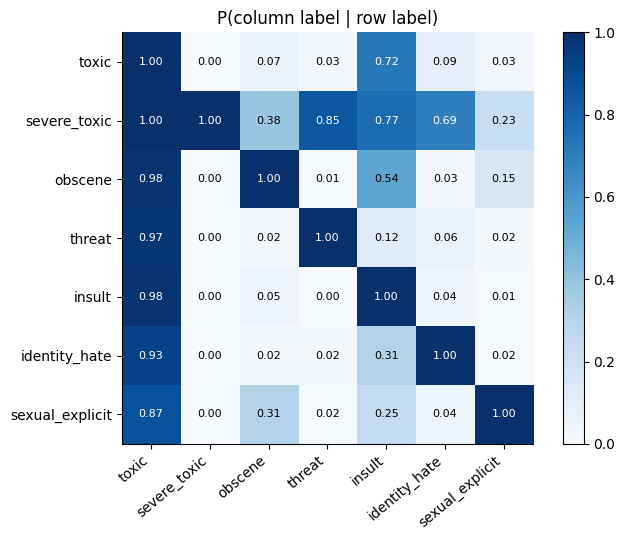

Labels with fewer than 1,000 positives at this threshold: ['severe_toxic']


In [6]:
B = pd.DataFrame({lab: (raw[col] >= LABEL_THRESHOLD) for lab, col in LABEL_SOURCE.items()})
prev = pd.DataFrame({"n_positive": B.sum(), "prevalence_%": (B.mean() * 100).round(3)})
display(prev)

co = pd.DataFrame({c: {r: (B[r] & B[c]).sum() / max(B[r].sum(), 1) for r in B.columns} for c in B.columns})
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(co.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(co))); ax.set_xticklabels(co.columns, rotation=40, ha="right"); ax.set_yticks(range(len(co))); ax.set_yticklabels(co.index)
for (i, j), v in np.ndenumerate(co.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.55 else "black", fontsize=8)
ax.set_title("P(column label | row label)"); plt.colorbar(im, fraction=0.04)
plt.tight_layout(); savefig("02_label_cooccurrence"); plt.show()

rare = prev.index[prev["n_positive"] < 1000].tolist()
print("Labels with fewer than 1,000 positives at this threshold:", rare or "none")

### 3.4 Annotator counts

Most comments were rated by only a handful of people, so one disagreeing rater moves a score a lot. The annotator count is **not available when a new comment arrives**, so it must never be used as a model input. We check whether it is also related to the label.

In [7]:
cnt = raw["toxicity_annotator_count"]
print(cnt.describe(percentiles=[.5, .9, .99]).round(1).to_string())

bucket = pd.cut(cnt, bins=[0, 4, 9, 19, np.inf], labels=["3-4", "5-9", "10-19", "20+"])
by_cnt = (raw.assign(bucket=bucket, toxic=(raw["target"] >= LABEL_THRESHOLD))
             .groupby("bucket", observed=True).agg(comments=("toxic", "size"), toxic_rate=("toxic", "mean")))
display(by_cnt.round(4))
lo_, hi_ = by_cnt["toxic_rate"].iloc[0], by_cnt["toxic_rate"].iloc[-1]
print(f"Toxic rate rises from {lo_:.2%} (fewest raters) to {hi_:.2%} (most raters): the count leaks the label, so it is excluded from modelling.")

count    1804874.0
mean           8.8
std           43.5
min            3.0
50%            4.0
90%           10.0
99%           75.0
max         4936.0


,comments,toxic_rate
bucket,,
3-4,1185465,0.0026
5-9,280010,0.0208
10-19,263549,0.3036
20+,75850,0.7310


Toxic rate rises from 0.26% (fewest raters) to 73.10% (most raters): the count leaks the label, so it is excluded from modelling.


## 4. Cleaning

### 4.1 The reusable module

All cleaning lives in `toxic_preprocessing.py`, so **Member 5's Streamlit app imports exactly the same function** used for training. If training and inference clean text differently, the deployed model performs worse than the reported numbers.

Order of operations in `clean_text`: repair mojibake, unescape HTML, Unicode NFKC, straighten curly quotes and dashes, remove zero-width/control characters, strip HTML tags, mask URLs (`[URL]`) and mentions (`@user`), squeeze 4+ repeated characters to 3 (`SOOOOO` becomes `SOOO`), collapse whitespace and line breaks.

Deliberately **not** done: removing punctuation or stop words, stemming, lowercasing (a separate `text_clean` column is lowercased for TF-IDF), emoji removal, or touching identity terms.

In [8]:
%%writefile toxic_preprocessing.py
"""Shared text cleaning for the toxic-comment project.
Use the SAME functions for training, evaluation and the Streamlit app."""
import re, html, codecs, unicodedata

# ---- mojibake repair: UTF-8 text that was decoded as Windows-1252, e.g. "I\u00e2\u20ac\u2122ll" -> "I'll" ----
_MOJIBAKE_HINT = re.compile("\u00c3|\u00c2|\u00e2\u20ac|\u00e2\u201a|\u00ef\u00bc|\u00e3\u0192|\u00cf\u2030|\u00f0\u0178")

def _c1_passthrough(exc):
    """Let cp1252 encoding pass through the 5 control chars it cannot represent (0x81, 0x8d, 0x8f, 0x90, 0x9d)."""
    if isinstance(exc, UnicodeEncodeError):
        bad = exc.object[exc.start:exc.end]
        if all(0x80 <= ord(c) <= 0x9F for c in bad):
            return bytes(ord(c) for c in bad), exc.end
    raise exc
codecs.register_error("c1passthrough", _c1_passthrough)

_MOJIBAKE_FALLBACK = {            # used when a string mixes mojibake with genuine non-cp1252 characters
    "\u00e2\u20ac\u2122": "'", "\u00e2\u20ac\u02dc": "'", "\u00e2\u20ac\u0153": '"', "\u00e2\u20ac\u009d": '"',
    "\u00e2\u20ac\u00a6": "...", "\u00e2\u20ac\u201d": " - ", "\u00e2\u20ac\u201c": " - ",
}

def fix_mojibake(text):
    if not _MOJIBAKE_HINT.search(text):
        return text
    try:
        return text.encode("cp1252", errors="c1passthrough").decode("utf-8")
    except UnicodeError:
        for bad, good in _MOJIBAKE_FALLBACK.items():
            text = text.replace(bad, good)
        return text

# ---- patterns ----
_URL_RE      = re.compile(r"(https?://\S+|www\.\S+)", re.IGNORECASE)
_HTML_TAG_RE = re.compile(r"</?[a-zA-Z][^>]*>")            # only real tags; keeps "<3" and "a < b"
_MENTION_RE  = re.compile(r"(?<!\w)@\w+")
_ZEROWIDTH   = re.compile(r"[\u200b-\u200f\u202a-\u202e\u2060\ufeff]")
_CONTROL_RE  = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]")
_REPEAT_RE   = re.compile(r"(.)\1{3,}")                    # 4+ identical chars -> 3
_SPACE_RE    = re.compile(r"\s+")
_PUNCT_MAP   = str.maketrans({"\u2018": "'", "\u2019": "'", "\u201a": "'", "\u201b": "'",
                              "\u201c": '"', "\u201d": '"', "\u201e": '"', "\u2013": " - ", "\u2014": " - ", "\u2212": "-"})

# used by the notebook to report how many comments each rule affects
PATTERNS = {
    "mojibake (encoding damage)": _MOJIBAKE_HINT,
    "HTML entities (&amp; ...)": re.compile(r"&(?:[a-zA-Z]+|#\d+|#x[0-9a-fA-F]+);"),
    "HTML tags": _HTML_TAG_RE,
    "URLs": _URL_RE,
    "@mentions": _MENTION_RE,
    "repeated characters (4+)": _REPEAT_RE,
    "line breaks / tabs": re.compile(r"[\r\n\t]"),
    "curly quotes / long dashes": re.compile("[\u2018\u2019\u201c\u201d\u2013\u2014]"),
    "zero-width / control chars": re.compile(_ZEROWIDTH.pattern + "|" + _CONTROL_RE.pattern),
}

def clean_text(text):
    """Light cleaning that preserves casing, punctuation and identity terms."""
    if not isinstance(text, str):
        return ""
    t = fix_mojibake(text)
    t = html.unescape(t)
    t = unicodedata.normalize("NFKC", t)
    t = t.translate(_PUNCT_MAP)
    t = _ZEROWIDTH.sub("", t)
    t = _CONTROL_RE.sub(" ", t)
    t = _HTML_TAG_RE.sub(" ", t)
    t = _URL_RE.sub(" [URL] ", t)
    t = _MENTION_RE.sub("@user", t)
    t = _REPEAT_RE.sub(r"\1\1\1", t)
    return _SPACE_RE.sub(" ", t).strip()

def clean_for_tfidf(text):
    """clean_text + lowercase, used for TF-IDF style models."""
    return clean_text(text).lower()

def has_content(text):
    """False if nothing is left once the placeholders are removed."""
    return bool(re.search(r"\w", text.replace("[URL]", "").replace("@user", "")))

Overwriting toxic_preprocessing.py


Quick test on real rows from `train.csv` (including the encoding-damaged ones):

In [9]:
from toxic_preprocessing import clean_text, clean_for_tfidf, has_content, fix_mojibake, PATTERNS

examples = [
    "Nice to some attempts to try to make comments betterâ€”it feels like any innovation ended with Disqus.",
    "Butâ€¦ if they really think there's a happy ending in this for any of them",
    "Personally, I already donâ€™t have the time or energy to actually read the stuff.",
    "Paula's written material is great! ï¼¼(ãƒ»Ï‰ãƒ»)/",
    "FFFFUUUUUUUUUUUUUUU",
    "Should be any day now according to http://yeezy-season2.com/",
    "Tuesday Jan. 13, members of \nthis socalled 'militia' traveled to\nJohn Day,Or",
    "I am a gay woman!!!!!!",
]
for e in examples:
    print("IN :", repr(e)); print("OUT:", repr(clean_text(e))); print()

IN : 'Nice to some attempts to try to make comments betterâ€”it feels like any innovation ended with Disqus.'
OUT: 'Nice to some attempts to try to make comments better - it feels like any innovation ended with Disqus.'

IN : "Butâ€¦ if they really think there's a happy ending in this for any of them"
OUT: "But... if they really think there's a happy ending in this for any of them"

IN : 'Personally, I already donâ€™t have the time or energy to actually read the stuff.'
OUT: "Personally, I already don't have the time or energy to actually read the stuff."

IN : "Paula's written material is great! ï¼¼(ãƒ»Ï‰ãƒ»)/"
OUT: "Paula's written material is great! \\(・ω・)/"

IN : 'FFFFUUUUUUUUUUUUUUU'
OUT: 'FFFUUU'

IN : 'Should be any day now according to http://yeezy-season2.com/'
OUT: 'Should be any day now according to [URL]'

IN : "Tuesday Jan. 13, members of \nthis socalled 'militia' traveled to\nJohn Day,Or"
OUT: "Tuesday Jan. 13, members of this socalled 'militia' traveled to John Day,Or"


### 4.2 What the raw text looks like: how many comments each rule will touch

In [10]:
txt = raw["comment_text"].fillna("")
impact = pd.DataFrame([{"issue": name, "comments_affected": int(txt.map(lambda s, rx=rx: bool(rx.search(s))).sum())}
                       for name, rx in PATTERNS.items()])
impact["share_%"] = (impact["comments_affected"] / len(raw) * 100).round(2)
display(impact.sort_values("comments_affected", ascending=False).reset_index(drop=True))
del txt

,issue,comments_affected,share_%
0,line breaks / tabs,565449,31.33
1,repeated characters (4+),138295,7.66
2,curly quotes / long dashes,62369,3.46
3,URLs,53221,2.95
4,@mentions,2688,0.15
5,HTML tags,1826,0.10
6,zero-width / control chars,989,0.05
7,HTML entities (&amp; ...),20,0.00
8,mojibake (encoding damage),0,0.00


### 4.3 Apply the cleaning pipeline

Steps, each logged with rows before and after:

1. Drop rows with no text.
2. Clean the text (`text_raw`: original casing, for transformers).
3. Drop empty, placeholder-only (nothing but `[URL]`/`@user`) or one-character comments.
4. **De-duplicate** identical texts (ignoring case and punctuation) and average their annotator scores.
5. Build binary labels, identity flags and meta-features.

In [11]:
t0 = time.time()
df = raw.rename(columns={"comment_text": "text_orig"}).copy()
del raw
log = []
def log_step(name, before, after, note=""):
    log.append({"step": name, "rows_before": before, "rows_after": after, "removed": before - after, "note": note})

# 1) no text
n = len(df); df = df[df["text_orig"].notna()].reset_index(drop=True)
log_step("drop missing text", n, len(df))

# 2) clean
df["text_raw"] = df["text_orig"].map(clean_text)
n_changed = int((df["text_raw"] != df["text_orig"]).sum())
print(f"Cleaned {len(df):,} comments in {time.time()-t0:.0f}s; {n_changed:,} ({n_changed/len(df):.1%}) were modified")

# 3) empty / placeholder-only / too short
n = len(df)
keep = df["text_raw"].map(has_content) & (df["text_raw"].str.len() >= 2)
df = df[keep].reset_index(drop=True)
log_step("drop empty / placeholder-only / <2 chars", n, len(df))

# 4) de-duplicate, averaging annotator scores of identical texts
score_cols = ["target", "severe_toxicity", "obscene", "identity_attack", "insult", "threat", "sexual_explicit"] + id_cols
score_cols = [c for c in score_cols if c in df.columns]
key = df["text_raw"].str.lower().str.replace(r"\W+", " ", regex=True).str.strip()
dup = key.duplicated(keep=False)
n_dup_rows, n_dup_groups = int(dup.sum()), int(key[dup].nunique())
n_conflict = 0
if dup.any():
    d = df.loc[dup, score_cols].copy(); d["_k"] = key[dup].values
    g = d.groupby("_k")
    n_conflict = int((g["target"].nunique() > 1).sum())
    df.loc[dup, score_cols] = g[score_cols].transform("mean")
n = len(df)
df = df.loc[~key.duplicated(keep="first")].reset_index(drop=True)
log_step("de-duplicate (scores averaged)", n, len(df),
         f"{n_dup_groups:,} duplicate groups; {n_conflict:,} had conflicting target scores")
del key, dup

print(f"\nDuplicate texts: {n_dup_rows:,} rows in {n_dup_groups:,} groups; {n_conflict:,} groups carried different toxicity scores -> averaged.")

Cleaned 1,804,871 comments in 353s; 1,034,192 (57.3%) were modified

Duplicate texts: 50,124 rows in 14,035 groups; 5,735 groups carried different toxicity scores -> averaged.


In [12]:
# 5) labels: keep the continuous annotator fraction as score_<label>, then binarize.
#    (score_* is created first because some label names equal their source column, e.g. "obscene")
for lab, col in LABEL_SOURCE.items():
    if col in df.columns:
        df[f"score_{lab}"] = df[col].astype("float32")
for lab, col in LABEL_SOURCE.items():
    if col in df.columns:
        df[lab] = (df[f"score_{lab}"] >= LABEL_THRESHOLD).astype("int8")
df = df.drop(columns=[c for c in LABEL_SOURCE.values() if c not in LABELS_ALL and c in df.columns])   # target, severe_toxicity, identity_attack
assert df[LABELS_ALL].isin([0, 1]).all().all() and all(f"score_{l}" in df.columns for l in LABELS_ALL)

# identity flags, meta-features, dates

df["has_identity_labels"] = df[id_cols].notna().any(axis=1)
df["mentions_identity"]   = df[id_cols].ge(IDENTITY_MENTION_THRESHOLD).any(axis=1)   # only meaningful where has_identity_labels

# signals that lowercasing would otherwise destroy, computed on text_raw
letters = df["text_raw"].str.count(r"[A-Za-z]")
upper   = df["text_raw"].str.count(r"[A-Z]")
df["n_chars"]        = df["text_raw"].str.len().astype("int32")
df["n_words"]        = df["text_raw"].str.split().str.len().astype("int32")
df["caps_ratio"]     = (upper / letters.replace(0, np.nan)).fillna(0).astype("float32")
df["exclaim_count"]  = df["text_raw"].str.count("!").astype("int16")
df["has_url"]        = df["text_raw"].str.contains("[URL]", regex=False)
del letters, upper

try:
    created = pd.to_datetime(df["created_date"], utc=True, errors="coerce", format="ISO8601")
except Exception:
    created = pd.to_datetime(df["created_date"], utc=True, errors="coerce")
df["created"] = created.dt.tz_localize(None)
df["year_month"] = df["created"].dt.strftime("%Y-%m")

# modelling labels: only those with enough positives
n_pos = df[LABELS_ALL].sum()
LABELS_MODEL = [l for l in LABELS_ALL if n_pos[l] >= MIN_POSITIVES_FOR_MODELLING]
print("Positives per label after cleaning:"); print(n_pos.to_string())
print(f"\nRecommended modelling labels (>= {MIN_POSITIVES_FOR_MODELLING} positives): {LABELS_MODEL}")
print(f"Kept in the file but NOT recommended for modelling: {[l for l in LABELS_ALL if l not in LABELS_MODEL]}")

Positives per label after cleaning:
toxic              141311
severe_toxic           13
obscene              9446
threat               4185
insult             104201
identity_hate       13179
sexual_explicit      4618

Recommended modelling labels (>= 500 positives): ['toxic', 'obscene', 'threat', 'insult', 'identity_hate', 'sexual_explicit']
Kept in the file but NOT recommended for modelling: ['severe_toxic']


### 4.4 Cleaning log and before/after examples

In [13]:
cleaning_log = pd.DataFrame(log)
display(cleaning_log)
print(f"Final dataset: {len(df):,} comments")

chg = df[df["text_raw"] != df["text_orig"]]
s = chg.sample(min(8, len(chg)), random_state=SEED)
fmt = lambda x: x.str.slice(0, 140).str.replace("\n", " ⏎ ", regex=False)
display(pd.DataFrame({"before": fmt(s["text_orig"]).values, "after": fmt(s["text_raw"]).values}))

df = df.drop(columns=["text_orig"])        # free memory; the cleaned text is in text_raw

,step,rows_before,rows_after,removed,note
0,drop missing text,1804874,1804871,3,
1,drop empty / placeholder-only / <2 chars,1804871,1802518,2353,
2,de-duplicate (scores averaged),1802518,1766429,36089,"14,035 duplicate groups; 5,735 had conflicting target scores"


Final dataset: 1,766,429 comments


,before,after
0,"It would appear that the U.S. is trying to shove ""terrorist attack"" down the German's throats but the Germ...","It would appear that the U.S. is trying to shove ""terrorist attack"" down the German's throats but the Germ..."
1,kudos to these anonymous donors. they gave a true gift - a self sustaining one. thank you - art lifts t...,kudos to these anonymous donors. they gave a true gift - a self sustaining one. thank you - art lifts the ...
2,"isn't this sick? yes, joseph should get the equivalent of punishment that he put that baby through. then...","isn't this sick? yes, joseph should get the equivalent of punishment that he put that baby through. then s..."
3,Nah....Satans got him...always had him.,Nah...Satans got him...always had him.
4,"Less ""TALK"" about football and what us being done. TALK is CHEAP even though the coaches are making money...","Less ""TALK"" about football and what us being done. TALK is CHEAP even though the coaches are making money ..."
5,"They should be named, shamed and charged as adults or kids will never learn. ⏎ It will only get worse bec...","They should be named, shamed and charged as adults or kids will never learn. It will only get worse becaus..."
6,"“The creatures outside looked from pig to man, and from man to pig, and from pig to man again; but already...","""The creatures outside looked from pig to man, and from man to pig, and from pig to man again; but already..."
7,Of all the lousy things Don Young has done over the years this vote was the worst. He is like Trump: self...,Of all the lousy things Don Young has done over the years this vote was the worst. He is like Trump: self ...


## 5. Exploratory analysis of the cleaned data

### 5.1 Comment length, capitalization and punctuation

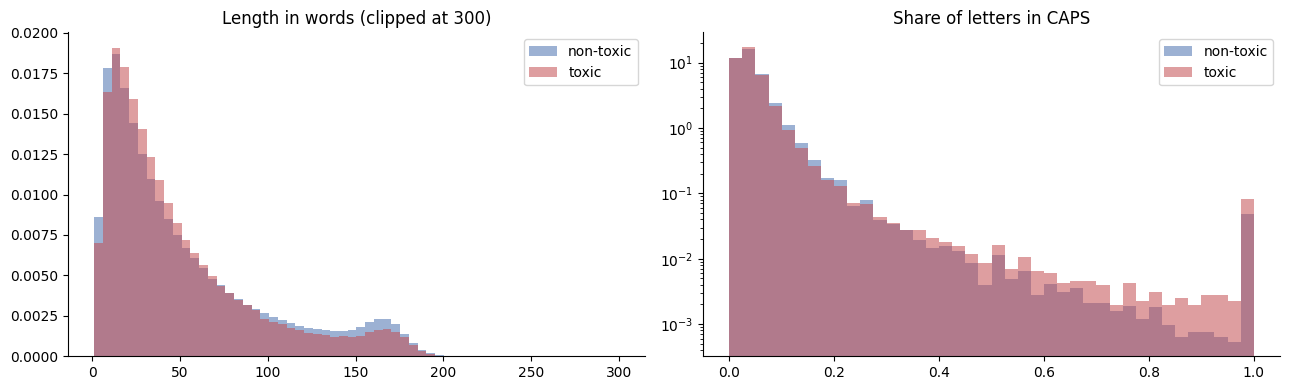

,comments,median_words,mean_caps_ratio,mean_exclaims,url_rate
toxic,,,,,
0,1625118,36.0,0.047,0.198,0.029
1,141311,35.0,0.047,0.329,0.013


Words per comment: median 36, p90 129, p95 159, p99 178
-> suggested transformer max_length ~ 240 tokens (p99 words x ~1.3 tokens/word, rounded up to a multiple of 16)


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for flag, name, color in [(0, "non-toxic", "#4c72b0"), (1, "toxic", "#c44e52")]:
    d = df[df["toxic"] == flag]
    ax[0].hist(d["n_words"].clip(upper=300), bins=60, alpha=0.55, density=True, label=name, color=color)
    ax[1].hist(d["caps_ratio"], bins=40, alpha=0.55, density=True, label=name, color=color)
ax[0].set_title("Length in words (clipped at 300)"); ax[0].legend()
ax[1].set_title("Share of letters in CAPS"); ax[1].set_yscale("log"); ax[1].legend()
plt.tight_layout(); savefig("03_length_caps"); plt.show()

by_class = df.groupby("toxic").agg(comments=("toxic", "size"), median_words=("n_words", "median"),
                                   mean_caps_ratio=("caps_ratio", "mean"), mean_exclaims=("exclaim_count", "mean"),
                                   url_rate=("has_url", "mean")).round(3)
display(by_class)

p = np.percentile(df["n_words"], [50, 90, 95, 99])
print(f"Words per comment: median {p[0]:.0f}, p90 {p[1]:.0f}, p95 {p[2]:.0f}, p99 {p[3]:.0f}")
SUGGESTED_MAX_LEN = int(min(512, np.ceil(p[3] * 1.3 / 16) * 16))
print(f"-> suggested transformer max_length ~ {SUGGESTED_MAX_LEN} tokens (p99 words x ~1.3 tokens/word, rounded up to a multiple of 16)")

### 5.2 Which words separate toxic from non-toxic comments?

Log ratio of how often a word appears in toxic vs non-toxic comments (document frequency, smoothed, words appearing in at least 50 comments of the sample). This is a sanity check that labels behave as expected and a preview of what a bag-of-words model will latch onto.

In [15]:
samp = df.sample(min(300_000, len(df)), random_state=SEED)
cv = CountVectorizer(lowercase=True, binary=True, min_df=50, stop_words="english",
                     token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']{2,}\b", dtype=np.int32)
Xs = cv.fit_transform(samp["text_raw"])
is_tox = samp["toxic"].values.astype(bool)
a = np.asarray(Xs[is_tox].sum(axis=0)).ravel(); b = np.asarray(Xs[~is_tox].sum(axis=0)).ravel()
words = np.array(cv.get_feature_names_out())
lr = np.log((a + 1) / (is_tox.sum() + 2)) - np.log((b + 1) / ((~is_tox).sum() + 2))
tbl = pd.DataFrame({"word": words, "log_ratio": lr.round(2), "in_toxic": a, "in_nontoxic": b}).sort_values("log_ratio", ascending=False)
print(f"Vocabulary: {len(words):,} words (sample of {len(samp):,} comments)")
display(pd.concat([tbl.head(15).reset_index(drop=True).add_prefix("TOXIC | "),
                   tbl.tail(15).iloc[::-1].reset_index(drop=True).add_prefix("CLEAN | ")], axis=1))
del Xs, samp

Vocabulary: 12,318 words (sample of 300,000 comments)


,TOXIC | word,TOXIC | log_ratio,TOXIC | in_toxic,TOXIC | in_nontoxic,CLEAN | word,CLEAN | log_ratio,CLEAN | in_toxic,CLEAN | in_nontoxic
0,fuck,4.79,62,5,compliance,-2.81,0,190
1,imbecile,4.56,57,6,zoning,-2.63,0,159
2,idiot,4.53,748,92,seed,-2.36,0,121
3,idiots,4.44,568,76,consult,-2.29,0,113
4,morons,4.17,162,28,maintained,-2.28,1,223
5,stupidity,4.15,524,94,ukrainian,-2.28,0,112
6,moron,4.15,263,47,ghg,-2.28,0,112
7,bitch,4.02,57,11,tfsa,-2.28,0,111
8,shit,3.93,132,29,decreased,-2.26,0,109
9,bullshit,3.93,65,14,hikes,-2.25,0,108


### 5.3 Time and moderation signal

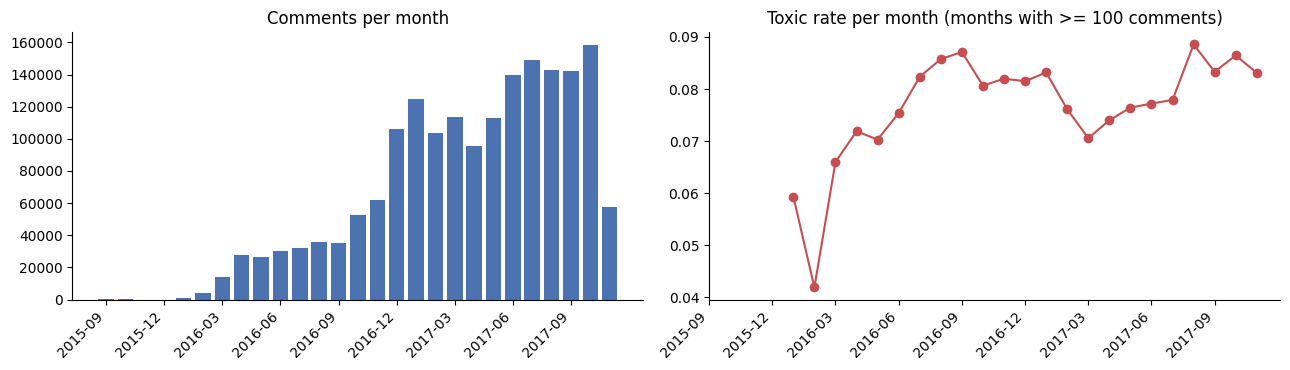

Date range: 2015-09-29 to 2017-11-11

Share of comments approved / rejected by the platform, by toxic label:


rating,approved,rejected
toxic,,
0,0.948,0.052
1,0.787,0.213


In [16]:
monthly = df.groupby("year_month").agg(comments=("toxic", "size"), toxic_rate=("toxic", "mean")).dropna()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(monthly.index, monthly["comments"], color="#4c72b0"); ax[0].set_title("Comments per month")
ax[1].plot(monthly.index, monthly["toxic_rate"].where(monthly["comments"] >= 100), marker="o", color="#c44e52")
ax[1].set_title("Toxic rate per month (months with >= 100 comments)")
for a_ in ax:
    a_.set_xticks(range(0, len(monthly), max(1, len(monthly) // 8))); a_.set_xticklabels(monthly.index[::max(1, len(monthly) // 8)], rotation=45, ha="right")
plt.tight_layout(); savefig("04_time_trend"); plt.show()
print(f"Date range: {df['created'].min():%Y-%m-%d} to {df['created'].max():%Y-%m-%d}")

if "rating" in df.columns:
    rj = pd.crosstab(df["toxic"], df["rating"], normalize="index").round(3)
    print("\nShare of comments approved / rejected by the platform, by toxic label:"); display(rj)

### 5.4 The core of the project: identity mentions and toxicity

For each of the 9 competition identity groups, among comments annotated as mentioning that group (fraction >= 0.5):

- **toxic_rate**: share labelled toxic. Compare it with the overall rate for comments that have identity annotations.
- **lift**: toxic_rate divided by that overall rate. A group with lift above 1 is over-represented among toxic training examples, which is exactly the pattern a model can wrongly learn as *"mentioning this group means toxic"*.
- **share_of_all_toxic**: how much of the toxic class this group accounts for.

Comments with identity annotations: 401,063   overall toxic rate among them: 11.32%


,identity,n_comments,toxic_rate,share_of_all_toxic,lift
0,black,14743,0.3117,0.1012,2.7533
1,homosexual_gay_or_lesbian,10898,0.2831,0.0679,2.5002
2,white,24702,0.2792,0.1519,2.4656
3,muslim,20677,0.2268,0.1033,2.0033
4,psychiatric_or_mental_illness,4838,0.2092,0.0223,1.8475
5,jewish,7549,0.1607,0.0267,1.4192
6,male,44136,0.1494,0.1452,1.3195
7,female,52980,0.1360,0.1587,1.2011
8,christian,40221,0.0905,0.0801,0.7989


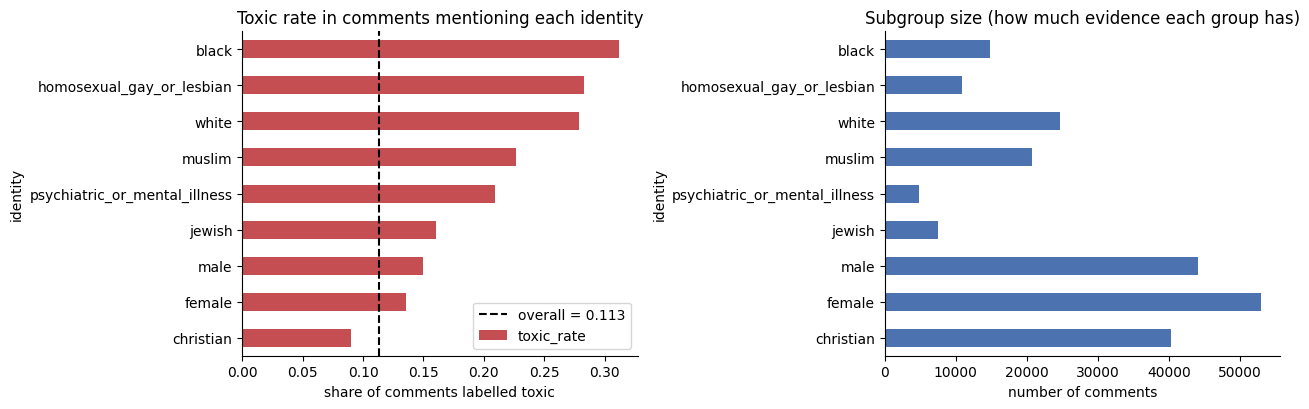

Groups with < 500 comments (subgroup metrics will be noisy): none


In [17]:
ann = df[df["has_identity_labels"]]
overall = ann["toxic"].mean()
rows = []
for g in [c for c in KEY_IDENTITIES if c in ann.columns]:
    m = ann[ann[g] >= IDENTITY_MENTION_THRESHOLD]
    rows.append({"identity": g, "n_comments": len(m), "toxic_rate": m["toxic"].mean() if len(m) else np.nan,
                 "share_of_all_toxic": (m["toxic"].sum() / ann["toxic"].sum()) if len(m) else np.nan})
ident = pd.DataFrame(rows)
ident["lift"] = ident["toxic_rate"] / overall
ident = ident.sort_values("toxic_rate", ascending=False).reset_index(drop=True)
print(f"Comments with identity annotations: {len(ann):,}   overall toxic rate among them: {overall:.2%}")
display(ident.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ident.iloc[::-1].plot.barh(x="identity", y="toxic_rate", ax=ax[0], legend=False, color="#c44e52")
ax[0].axvline(overall, color="black", ls="--", label=f"overall = {overall:.3f}"); ax[0].legend()
ax[0].set_xlabel("share of comments labelled toxic"); ax[0].set_title("Toxic rate in comments mentioning each identity")
ident.iloc[::-1].plot.barh(x="identity", y="n_comments", ax=ax[1], legend=False, color="#4c72b0")
ax[1].set_xlabel("number of comments"); ax[1].set_title("Subgroup size (how much evidence each group has)")
plt.tight_layout(); savefig("05_identity_toxicity"); plt.show()
ident.to_csv(OUT_DIR / "eda_identity_toxicity.csv", index=False)

small = ident.loc[ident["n_comments"] < 500, "identity"].tolist()
print("Groups with < 500 comments (subgroup metrics will be noisy):", small or "none")

The same question from the **text** side: for comments that literally contain an identity word, what share are toxic? Annotation-based and word-based views usually disagree a little; both are worth reporting.

In [18]:
terms = ["gay", "lesbian", "transgender", "muslim", "muslims", "jewish", "christian", "atheist", "black", "white",
         "asian", "woman", "women", "man", "men", "blind", "deaf", "disabled", "mental", "straight"]
cvt = CountVectorizer(vocabulary=terms, binary=True, lowercase=True)
Xt = cvt.transform(df["text_raw"])
tox = df["toxic"].values.astype(bool)
rows = []
for i, t in enumerate(terms):
    col = Xt[:, i].toarray().ravel().astype(bool)
    rows.append({"word": t, "n_comments": int(col.sum()), "toxic_rate": float(tox[col].mean()) if col.sum() else np.nan})
lex = pd.DataFrame(rows).sort_values("toxic_rate", ascending=False).reset_index(drop=True)
print(f"Overall toxic rate (all comments): {tox.mean():.2%}")
display(lex.round(4))
del Xt

Overall toxic rate (all comments): 8.00%


,word,n_comments,toxic_rate
0,lesbian,471,0.3270
1,gay,6158,0.2975
2,muslims,8714,0.2509
3,black,18987,0.2307
4,white,37517,0.2240
5,muslim,10260,0.2173
6,transgender,1491,0.1918
7,mental,7729,0.1511
8,blind,5000,0.1452
9,woman,16669,0.1436


## 6. Train / validation / test split

- **Grouped by `article_id`** (`StratifiedGroupKFold`): all comments under one article land in the same split, so topic words and quoted text cannot leak from train to test.
- **Stratified** on `toxic` x `mentions_identity` x `identity_hate`, so toxic, identity-related and identity-hate comments appear in every split in the same proportions.
- Fixed `SEED`; one saved file per split with a `split` column, so every member evaluates on identical rows.
- **Fairness audit (Member 3):** `split == "test"` and `has_identity_labels == True`.

In [19]:
strat_key = (df["toxic"].astype(int) * 4 + (df["mentions_identity"] & df["has_identity_labels"]).astype(int) * 2
             + df["identity_hate"].astype(int)).values
use_groups = "article_id" in df.columns and df["article_id"].notna().all()

folds = np.full(len(df), -1)
if use_groups:
    splitter = StratifiedGroupKFold(n_splits=N_SPLIT_FOLDS, shuffle=True, random_state=SEED)
    for i, (_, idx) in enumerate(splitter.split(np.zeros(len(df)), strat_key, df["article_id"].values)):
        folds[idx] = i
else:
    print("article_id not available: falling back to a stratified random split.")
    from sklearn.model_selection import StratifiedKFold
    for i, (_, idx) in enumerate(StratifiedKFold(N_SPLIT_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(df)), strat_key)):
        folds[idx] = i

df["split"] = np.where(folds == 0, "test", np.where(folds == 1, "val", "train"))

if use_groups:
    arts = {s: set(df.loc[df["split"] == s, "article_id"]) for s in ["train", "val", "test"]}
    assert not (arts["train"] & arts["test"]) and not (arts["train"] & arts["val"]) and not (arts["val"] & arts["test"])
    print("OK: no article appears in more than one split.")

summary = df.groupby("split").agg(comments=("toxic", "size"), toxic_rate=("toxic", "mean"),
                                  identity_annotated=("has_identity_labels", "mean"),
                                  identity_hate_rate=("identity_hate", "mean")).loc[["train", "val", "test"]]
summary["share_of_data"] = summary["comments"] / len(df)
display(summary.round(4))
print("Positives per label and split:")
display(df.groupby("split")[LABELS_ALL].sum().loc[["train", "val", "test"]])

OK: no article appears in more than one split.


,comments,toxic_rate,identity_annotated,identity_hate_rate,share_of_data
split,,,,,
train,1413142,0.08,0.2269,0.0075,0.8
val,176643,0.08,0.2267,0.0075,0.1
test,176644,0.08,0.2284,0.0075,0.1


Positives per label and split:


,toxic,severe_toxic,obscene,threat,insult,identity_hate,sexual_explicit
split,,,,,,,
train,113049,11,7540,3328,83295,10543,3770
val,14131,1,965,450,10454,1318,428
test,14131,1,941,407,10452,1318,420


In [20]:
# Are there enough test comments per identity group for a meaningful audit?
rows = []
for g in [c for c in KEY_IDENTITIES if c in df.columns]:
    for s in ["val", "test"]:
        m = df[(df["split"] == s) & df["has_identity_labels"] & (df[g] >= IDENTITY_MENTION_THRESHOLD)]
        rows.append({"identity": g, "split": s, "n": len(m), "n_toxic": int(m["toxic"].sum()), "n_nontoxic": int((m["toxic"] == 0).sum())})
sg = pd.DataFrame(rows).pivot(index="identity", columns="split", values=["n", "n_toxic", "n_nontoxic"])
display(sg)
weak = sg.index[(sg[("n_toxic", "test")] < 50) | (sg[("n_nontoxic", "test")] < 50)].tolist()
print("Groups with < 50 toxic or < 50 non-toxic test comments (interpret their metrics with caution):", weak or "none")

# class-imbalance weights from TRAIN only (neg / pos), for Member 2's loss function
train = df[df["split"] == "train"]
pos_weight = {l: round((len(train) - int(train[l].sum())) / max(int(train[l].sum()), 1), 2) for l in LABELS_MODEL}
print("\npos_weight (train only):", pos_weight)

n       n_toxic      n_nontoxic      
split                          test   val    test  val       test   val
identity                                                               
black                          1506  1541     435  483       1071  1058
christian                      4480  4038     397  395       4083  3643
female                         4767  5261     650  666       4117  4595
homosexual_gay_or_lesbian       891  1115     265  286        626   829
jewish                          734   762     126  114        608   648
male                           4161  4336     622  647       3539  3689
muslim                         2284  2092     508  475       1776  1617
psychiatric_or_mental_illness   489   448     116   96        373   352
white                          2501  2528     689  690       1812  1838

Groups with < 50 toxic or < 50 non-toxic test comments (interpret their metrics with caution): none

pos_weight (train only): {'toxic': 11.5, 'obscene': 186.42, 'threat': 423.62, 'insult': 15.97, 'identity_hate': 133.04, 'sexual_explicit': 373.84}


## 7. Save the cleaned dataset and metadata

In [21]:
KEEP = (["id", "text_raw", "text_clean"] + LABELS_ALL + [f"score_{l}" for l in LABELS_ALL] +
        id_cols + ["has_identity_labels", "mentions_identity", "n_chars", "n_words", "caps_ratio", "exclaim_count", "has_url",
                   "created", "article_id", "publication_id", "rating", "likes", "disagree",
                   "toxicity_annotator_count", "identity_annotator_count", "split"])
KEEP = list(dict.fromkeys(KEEP))                      # no duplicate names

def save_df(d, name):
    try:
        d.to_parquet(OUT_DIR / f"{name}.parquet", index=False); return f"{name}.parquet"
    except Exception as e:                             # pyarrow missing or dtype problem -> csv fallback
        print(f"  parquet failed for {name} ({type(e).__name__}: {str(e)[:160]}); saving csv.gz instead")
        d.to_csv(OUT_DIR / f"{name}.csv.gz", index=False); return f"{name}.csv.gz"

saved = []
for s in ["train", "val", "test"]:
    part = df[df["split"] == s].copy()
    part["text_clean"] = part["text_raw"].str.lower()            # lowercased copy for TF-IDF models
    saved.append(save_df(part[[c for c in KEEP if c in part.columns]].reset_index(drop=True), s))
print("Saved:", saved)

cleaning_log.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
impact.to_csv(OUT_DIR / "cleaning_impact.csv", index=False)
prev.to_csv(OUT_DIR / "eda_label_prevalence.csv")

card = {
    "source_file": str(jigsaw_path), "rows_final": int(len(df)),
    "splits": df["split"].value_counts().to_dict(),
    "labels_all": LABELS_ALL, "labels_model": LABELS_MODEL, "pos_weight": pos_weight,
    "text_columns": {"transformer": "text_raw", "tfidf": "text_clean"},
    "suggested_max_length": SUGGESTED_MAX_LEN,
    "split_method": "StratifiedGroupKFold by article_id" if use_groups else "StratifiedKFold",
    "fairness_subset": "split == 'test' & has_identity_labels == True; identity columns are annotator fractions (>= 0.5 = mentioned)",
    "config": {"seed": SEED, "label_threshold": LABEL_THRESHOLD, "identity_mention_threshold": IDENTITY_MENTION_THRESHOLD,
               "min_positives_for_modelling": MIN_POSITIVES_FOR_MODELLING, "max_rows": MAX_ROWS},
    "cleaning_log": cleaning_log.to_dict("records"),
}
(OUT_DIR / "dataset_card.json").write_text(json.dumps(card, indent=2, default=str))
print("\nFiles in", OUT_DIR, ":", sorted(p.name for p in OUT_DIR.iterdir()))
print("Figures:", sorted(p.name for p in FIG_DIR.iterdir()))

Saved: ['train.parquet', 'val.parquet', 'test.parquet']

Files in processed_data : ['cleaning_impact.csv', 'cleaning_log.csv', 'dataset_card.json', 'eda_identity_toxicity.csv', 'eda_label_prevalence.csv', 'figures', 'test.parquet', 'train.parquet', 'val.parquet']
Figures: ['01_target_distribution.png', '02_label_cooccurrence.png', '03_length_caps.png', '04_time_trend.png', '05_identity_toxicity.png']


## 8. Hand-off notes and known limitations

| Member | Use |
|---|---|
| **2 (DistilBERT)** | `train/val/test.parquet`; input `text_raw`; labels from `labels_model` in `dataset_card.json`; `pos_weight` for the loss; `suggested_max_length`. Continuous annotator fractions (`score_toxic`, `score_insult`, ...) are available for soft-label experiments |
| **3 (Fairness)** | Subset `split == "test" & has_identity_labels`; the 24 identity columns hold annotator fractions (>= 0.5 = mentioned); `eda_identity_toxicity.csv` has the baseline disparity numbers; check subgroup sizes before trusting a metric |
| **4 (Explainability)** | `text_clean` for TF-IDF/SHAP; meta-features `caps_ratio`, `exclaim_count` |
| **5 (Streamlit)** | `from toxic_preprocessing import clean_text` before every prediction, so inference matches training |

**Limitations to state in the report**

1. **Labels are crowd fractions from few raters** (often 4), so comments near the threshold are noisy; the threshold choice changes the class balance (section 3.2).
2. **Rare labels.** Labels below `MIN_POSITIVES_FOR_MODELLING` positives are kept in the file but not recommended for modelling; `threat` is rare even when it qualifies.
3. **Identity annotations cover only part of the data.** A missing value means "not annotated", not "no identity". `mentions_identity` is meaningful only where `has_identity_labels` is True.
4. **`toxicity_annotator_count` must not be a model feature.** It is not available at inference, and section 3.4 shows it is strongly related to the label (comments rated by many people are far more often toxic).
5. Line breaks are collapsed to spaces, which loses paragraph structure. English only; obfuscated spellings (e.g. `id10t`) are not normalized.
6. Comments come from news-site discussions (2015 to 2017), so models may transfer poorly to other platforms.